# Experiment 08 — External Paper Reproduction

## E7 — DeepKoopFormer Temporal Order Comparison

### 1. Mục tiêu

Mở rộng thí nghiệm **Temporal Order Sensitivity** từ bài báo *Are Transformers Effective for Long Sequence Time-Series Forecasting?* sang mô hình DeepKoopFormer.

So sánh mức độ nhạy cảm với thứ tự thời gian giữa **LTSF-Linear** và **DeepKoopFormer**, nhằm đánh giá ảnh hưởng của việc thay đổi cấu trúc thời gian trong chuỗi đầu vào.

### 2. Thiết kế thực nghiệm

**Dataset:** ETTh1 — 7 channels.

**Models:**
- LTSF-Linear — baseline đã tái thực nghiệm.
- KoopPatchTST_Full — biến thể đầy đủ của DeepKoopFormer.

**Experimental Configuration:**
- Input Sequence Length: 96.
- Forecasting Horizons: 96, 192, 336, 720.
- Random Seeds: 7, 17, 27, 37, 47.
- Train/Validation/Test Split: Giữ nguyên từ `01_etth1_data.ipynb`.
- Normalization: StandardScaler.

### 3. Temporal Order Transformations

Áp dụng ba điều kiện đánh giá:

- **Original:** Giữ nguyên thứ tự thời gian.
- **Shuffle:** Hoán vị ngẫu nhiên thứ tự timestamps.
- **Half-Exchange:** Hoán đổi hai nửa chuỗi đầu vào.

Sử dụng cùng dữ liệu Test và phép biến đổi như thí nghiệm Linear.

### 4. Quy trình thực hiện

1. Nạp ETTh1 đã tiền xử lý.
2. Khởi tạo DeepKoopFormer theo kiến trúc đã triển khai.
3. Huấn luyện DeepKoopFormer trên ETTh1.
4. Lưu checkpoint tốt nhất theo Validation.
5. Đánh giá mô hình trên ba điều kiện Original, Shuffle và Half-Exchange.
6. So sánh MSE, MAE và Relative Performance Degradation với Linear.
7. Lưu kết quả và trực quan hóa.

### 5. Kết quả đầu ra

- Checkpoints DeepKoopFormer trên ETTh1.
- `deepkoopformer_metrics.csv` — Kết quả theo horizon, seed và transformation.
- `model_comparison.csv` — Bảng so sánh Linear và DeepKoopFormer.
- Biểu đồ MSE, MAE và Relative Degradation.

Thực nghiệm mở rộng nhằm đánh giá mức độ phụ thuộc vào thứ tự thời gian của DeepKoopFormer trong cùng giao thức kiểm tra với Linear.

DEEPKOOPFORMER: ENVIRONMENT & ARCHITECTURE

In [5]:
from pathlib import Path
import sys
import hashlib
import random

import numpy as np
import pandas as pd
import torch

# 1. Reproducibility
SEED = 7
EVAL_SEEDS = [7, 17, 27, 37, 47]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Locate project root
PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "datasets" / "ETTh1" / "ETTh1.csv"
        ).is_file()
    ),
    None
)

assert PROJECT_ROOT is not None, "Project root not found"

EXTERNAL_DIR = (
    PROJECT_ROOT / "experiments" / "08_external_paper"
)

ABLATION_DIR = (
    PROJECT_ROOT / "experiments" / "05_ablation"
)

PREPARED_PATH = (
    EXTERNAL_DIR / "results"
    / "etth1_data" / "etth1_prepared.pt"
)

MODEL_NOTEBOOK = (
    ABLATION_DIR / "02_ablation_model.ipynb"
)

TRAINER_PATH = (
    ABLATION_DIR / "train_ablation_v2.py"
)

LINEAR_METRICS_PATH = (
    EXTERNAL_DIR / "results"
    / "temporal_order_test"
    / "temporal_order_metrics.csv"
)

RESULTS_DIR = (
    EXTERNAL_DIR / "results"
    / "deepkoopformer_comparison"
)

KOOP_MODEL_DIR = RESULTS_DIR / "models"
KOOP_MODEL_DIR.mkdir(parents=True, exist_ok=True)

for path in [
    PREPARED_PATH,
    MODEL_NOTEBOOK,
    TRAINER_PATH,
    LINEAR_METRICS_PATH
]:
    assert path.is_file(), f"Missing: {path}"

# 3. Load prepared ETTh1
bundle = torch.load(
    PREPARED_PATH,
    map_location="cpu",
    weights_only=True
)

assert bundle["dataset"] == "ETTh1"
assert bundle["normalization"] == "StandardScaler"

SEQ_LEN = int(bundle["seq_len"])
PRED_LENGTHS = list(bundle["pred_lengths"])
N_CHANNELS = int(bundle["channels"])

ETTH1_SPLITS = {
    split: bundle[split].float()
    for split in ["train", "val", "test"]
}

SCALER_MEAN = bundle["scaler_mean"]
SCALER_SCALE = bundle["scaler_scale"]

assert SEQ_LEN == 96
assert PRED_LENGTHS == [96, 192, 336, 720]
assert N_CHANNELS == 7

assert ETTH1_SPLITS["train"].shape == (8640, 7)
assert ETTH1_SPLITS["val"].shape == (2976, 7)
assert ETTH1_SPLITS["test"].shape == (2976, 7)

for series in ETTH1_SPLITS.values():
    assert torch.isfinite(series).all()

# 4. Load actual model definitions from Ablation
sys.path.insert(0, str(ABLATION_DIR))

import train_ablation_v2 as ablation_core

MODEL_NAMESPACE = ablation_core.load_model_notebook(
    MODEL_NOTEBOOK
)

create_ablation_model = MODEL_NAMESPACE[
    "create_ablation_model"
]

StrictStableKoopmanOperator = MODEL_NAMESPACE[
    "StrictStableKoopmanOperator"
]

MODEL_SHA256 = hashlib.sha256(
    MODEL_NOTEBOOK.read_bytes()
).hexdigest()

# 5. Check experimental architecture settings
MODEL_NAME = "KoopPatchTST_Full"

PATCH_LEN = SEQ_LEN
STRIDE = PATCH_LEN

D_MODEL = ablation_core.D_MODEL
D_LATENT = ablation_core.D_LATENT
RHO_MAX = ablation_core.RHO_MAX
LYAP_WEIGHT = ablation_core.LYAP_WEIGHT

assert D_MODEL == 96
assert D_LATENT == 96
assert RHO_MAX == 0.99
assert LYAP_WEIGHT == 0.1

assert SEQ_LEN % PATCH_LEN == 0

N_PATCH_TOKENS = SEQ_LEN // PATCH_LEN

assert N_PATCH_TOKENS == 1

# 6. Validate pretrained Linear results are available
linear_df = pd.read_csv(LINEAR_METRICS_PATH)

assert len(linear_df) == 60

assert set(linear_df["Transformation"]) == {
    "Original",
    "Shuffle",
    "Half-Exchange"
}

assert set(linear_df["Horizon"]) == set(PRED_LENGTHS)
assert set(linear_df["Seed"]) == set(EVAL_SEEDS)

# 7. Architecture compatibility for each horizon
architecture_rows = []

X_dummy = (
    ETTH1_SPLITS["train"][:SEQ_LEN]
    .unsqueeze(0)
    .repeat(2, 1, 1)
    .to(DEVICE)
)

for horizon in PRED_LENGTHS:

    torch.manual_seed(SEED)

    model, koop_attr, lyap_weight = (
        create_ablation_model(
            model_name=MODEL_NAME,
            input_dim=N_CHANNELS,
            patch_len=PATCH_LEN,
            horizon=horizon
        )
    )

    model = model.to(DEVICE)
    model.eval()

    # Verify actual architecture
    assert isinstance(
        model.koop,
        StrictStableKoopmanOperator
    )

    assert koop_attr == "koop"
    assert lyap_weight == LYAP_WEIGHT

    assert model.backbone.patch.conv.kernel_size == (
        PATCH_LEN,
    )

    assert model.backbone.patch.conv.stride == (
        STRIDE,
    )

    assert model.fc.out_features == (
        horizon * N_CHANNELS
    )

    # Verify forward pass and latent representations
    with torch.inference_mode():

        prediction, z, z_next = model(
            X_dummy,
            return_latents=True
        )

        direct_prediction = model(X_dummy)

        _, K, singular_values = model.koop(z)

    assert prediction.shape == (
        2, horizon * N_CHANNELS
    )

    assert z.shape == (2, D_LATENT)
    assert z_next.shape == (2, D_LATENT)

    torch.testing.assert_close(
        prediction,
        direct_prediction
    )

    assert torch.isfinite(prediction).all()
    assert torch.isfinite(z).all()
    assert torch.isfinite(z_next).all()

    # Verify Koopman stability constraint
    sigma_max = float(
        torch.linalg.svdvals(K).max().item()
    )

    assert sigma_max < RHO_MAX + 1e-5

    # Verify target layout (feature-major)
    Y_example = ETTH1_SPLITS["train"][
        SEQ_LEN:SEQ_LEN + horizon
    ]

    Y_flat = (
        Y_example.T.contiguous()
        .reshape(1, -1)
    )

    assert Y_flat.shape == (
        1, horizon * N_CHANNELS
    )

    params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    architecture_rows.append({
        "Horizon": horizon,
        "Input": str(tuple(X_dummy.shape)),
        "Prediction": str(tuple(prediction.shape)),
        "Latent": str(tuple(z.shape)),
        "Patch_Tokens": N_PATCH_TOKENS,
        "Parameters": params,
        "Sigma_Max": sigma_max,
        "Lyap_Weight": lyap_weight,
        "Status": "PASSED"
    })

    del model

# 8. Save architecture verification
ARCHITECTURE_DF = pd.DataFrame(
    architecture_rows
)

assert len(ARCHITECTURE_DF) == 4

assert (
    ARCHITECTURE_DF["Status"] == "PASSED"
).all()

ARCHITECTURE_DF.to_csv(
    RESULTS_DIR / "architecture_validation.csv",
    index=False
)

# 9. Summary
print("=== E7 — DEEPKOOPFORMER COMPATIBILITY ===")

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset: ETTh1")
print("Train:", tuple(ETTH1_SPLITS["train"].shape))
print("Val:", tuple(ETTH1_SPLITS["val"].shape))
print("Test:", tuple(ETTH1_SPLITS["test"].shape))

print("\nModel:", MODEL_NAME)
print("Input sequence:", SEQ_LEN)
print("Patch length:", PATCH_LEN)
print("Patch tokens:", N_PATCH_TOKENS)
print("Latent dimension:", D_LATENT)
print("Rho max:", RHO_MAX)
print("Lyapunov weight:", LYAP_WEIGHT)

print("\nForecast horizons:", PRED_LENGTHS)
print("Random seeds:", EVAL_SEEDS)
print("Planned training runs:",
      len(PRED_LENGTHS) * len(EVAL_SEEDS))

print("\nModel SHA256:", MODEL_SHA256)

print("\n=== ARCHITECTURE VALIDATION ===")
display(ARCHITECTURE_DF.round(6))

print("\nLinear baseline rows:", len(linear_df))
print("All forward passes: PASSED")
print("Koopman constraint: PASSED")
print("Target layout: VERIFIED")
print("Training performed: NO")

print("\nDEEPKOOPFORMER COMPATIBILITY PASSED!")


=== E7 — DEEPKOOPFORMER COMPATIBILITY ===
Project: c:\Users\Win 11 New\Desktop\pa gk
Device: cuda
GPU: Quadro T1000

Dataset: ETTh1
Train: (8640, 7)
Val: (2976, 7)
Test: (2976, 7)

Model: KoopPatchTST_Full
Input sequence: 96
Patch length: 96
Patch tokens: 1
Latent dimension: 96
Rho max: 0.99
Lyapunov weight: 0.1

Forecast horizons: [96, 192, 336, 720]
Random seeds: [7, 17, 27, 37, 47]
Planned training runs: 20

Model SHA256: 74b449a8ff1b6eb5a6ce0d25c272dc8491973f58aeb3f9295e44c59a4ab49bed

=== ARCHITECTURE VALIDATION ===


,Horizon,Input,Prediction,Latent,Patch_Tokens,Parameters,Sigma_Max,Lyap_Weight,Status
0,96,"(2, 96, 7)","(2, 672)","(2, 96)",1,317184,0.902589,0.1,PASSED
1,192,"(2, 96, 7)","(2, 1344)","(2, 96)",1,382368,0.902589,0.1,PASSED
2,336,"(2, 96, 7)","(2, 2352)","(2, 96)",1,480144,0.902589,0.1,PASSED
3,720,"(2, 96, 7)","(2, 5040)","(2, 96)",1,740880,0.902589,0.1,PASSED



Linear baseline rows: 60
All forward passes: PASSED
Koopman constraint: PASSED
Target layout: VERIFIED
Training performed: NO

DEEPKOOPFORMER COMPATIBILITY PASSED!


DEEPKOOPFORMER TRAINING PROTOCOL & DATALOADERS

In [6]:
import json
from torch.utils.data import Dataset, DataLoader

# 1. Training configuration
TRAIN_CONFIG = {
    "epochs": 4000,
    "learning_rate": 3e-4,
    "optimizer": "Adam",
    "loss": "MSE + Lyapunov",
    "lyap_weight": LYAP_WEIGHT,
    "rho_max": RHO_MAX,
    "batch_strategy": "full_batch",
    "eval_batch_size": 256,
    "validation_every": 50,
    "checkpoint_every": 100,
    "early_stopping": False,
    "checkpoint_selection": "best_validation_mse",
    "num_workers": 0
}

# One optimizer update per epoch, matching Ablation.
# Validation is checked every 50 epochs.
# All 4000 epochs are retained; no early stopping.


# 2. Sliding Window Dataset
class KoopWindowDataset(Dataset):

    def __init__(self, series, seq_len, pred_len):
        self.series = series
        self.seq_len = int(seq_len)
        self.pred_len = int(pred_len)

        assert series.ndim == 2
        assert series.shape[1] == N_CHANNELS
        assert len(series) >= seq_len + pred_len

    def __len__(self):
        return (
            len(self.series)
            - self.seq_len
            - self.pred_len
            + 1
        )

    def __getitem__(self, idx):

        if idx < 0 or idx >= len(self):
            raise IndexError(idx)

        x_end = idx + self.seq_len
        y_end = x_end + self.pred_len

        X = self.series[idx:x_end]
        Y = self.series[x_end:y_end]

        return X, Y


# 3. Construct datasets and dataloaders
KOOP_DATASETS = {}
KOOP_LOADERS = {}

rows = []

for horizon in PRED_LENGTHS:

    datasets = {
        split: KoopWindowDataset(
            series=ETTH1_SPLITS[split],
            seq_len=SEQ_LEN,
            pred_len=horizon
        )
        for split in ["train", "val", "test"]
    }

    # Full-batch Train, batched Val/Test
    loaders = {
        "train": DataLoader(
            datasets["train"],
            batch_size=len(datasets["train"]),
            shuffle=False,
            drop_last=False,
            num_workers=0
        ),
        "val": DataLoader(
            datasets["val"],
            batch_size=TRAIN_CONFIG["eval_batch_size"],
            shuffle=False,
            drop_last=False,
            num_workers=0
        ),
        "test": DataLoader(
            datasets["test"],
            batch_size=TRAIN_CONFIG["eval_batch_size"],
            shuffle=False,
            drop_last=False,
            num_workers=0
        )
    }

    KOOP_DATASETS[horizon] = datasets
    KOOP_LOADERS[horizon] = loaders

    for split in ["train", "val", "test"]:

        ds = datasets[split]
        loader = loaders[split]

        X_first, Y_first = ds[0]
        X_last, Y_last = ds[len(ds) - 1]

        assert X_first.shape == (SEQ_LEN, N_CHANNELS)
        assert Y_first.shape == (horizon, N_CHANNELS)

        assert X_last.shape == X_first.shape
        assert Y_last.shape == Y_first.shape

        assert torch.isfinite(X_first).all()
        assert torch.isfinite(Y_first).all()
        assert torch.isfinite(X_last).all()
        assert torch.isfinite(Y_last).all()

        # Verify the first window against source data
        series = ETTH1_SPLITS[split]

        assert torch.equal(
            X_first,
            series[:SEQ_LEN]
        )

        assert torch.equal(
            Y_first,
            series[SEQ_LEN:SEQ_LEN + horizon]
        )

        # Verify that the last target is inside the split
        assert torch.equal(
            Y_last,
            series[-horizon:]
        )

        # Feature-major targets expected by DeepKoopFormer
        Y_flat = (
            Y_first.T.contiguous().reshape(-1)
        )

        assert Y_flat.shape == (
            horizon * N_CHANNELS,
        )

        assert torch.equal(
            Y_flat.reshape(N_CHANNELS, horizon).T,
            Y_first
        )

        rows.append({
            "Horizon": horizon,
            "Split": split,
            "Windows": len(ds),
            "Batches": len(loader),
            "X_Shape": str(tuple(X_first.shape)),
            "Y_Shape": str(tuple(Y_first.shape)),
            "Status": "PASSED"
        })


# 4. Verify split boundaries and label isolation
assert bundle["split_borders"]["train"] == (0, 8640)
assert bundle["split_borders"]["val"] == (8544, 11520)
assert bundle["split_borders"]["test"] == (11424, 14400)

assert torch.equal(
    ETTH1_SPLITS["val"][:SEQ_LEN],
    ETTH1_SPLITS["train"][-SEQ_LEN:]
)

assert torch.equal(
    ETTH1_SPLITS["test"][:SEQ_LEN],
    ETTH1_SPLITS["val"][-SEQ_LEN:]
)

# 5. Verify training configuration
assert TRAIN_CONFIG["epochs"] == 4000
assert TRAIN_CONFIG["learning_rate"] == 3e-4
assert TRAIN_CONFIG["lyap_weight"] == 0.1
assert TRAIN_CONFIG["rho_max"] == 0.99

assert all(
    len(KOOP_LOADERS[h]["train"]) == 1
    for h in PRED_LENGTHS
)

# 6. Save reproducible training protocol
TRAINING_PROTOCOL = {
    "experiment": "DeepKoopFormer Temporal Order Comparison",
    "dataset": "ETTh1",
    "model": MODEL_NAME,
    "source_sha256": bundle["source_sha256"],
    "model_sha256": MODEL_SHA256,
    "sequence_length": SEQ_LEN,
    "patch_length": PATCH_LEN,
    "channels": N_CHANNELS,
    "forecasting_horizons": PRED_LENGTHS,
    "seeds": EVAL_SEEDS,
    "normalization": "StandardScaler (Train only)",
    "training": TRAIN_CONFIG,
    "note": (
        "Uses Ablation architecture and main optimization "
        "hyperparameters. Adds validation checkpoint selection. "
        "Not an exact reproduction of the original paper's "
        "training protocol."
    )
}

PROTOCOL_PATH = (
    RESULTS_DIR / "training_protocol.json"
)

PROTOCOL_PATH.write_text(
    json.dumps(
        TRAINING_PROTOCOL,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# 7. Summary
LOADER_SUMMARY = pd.DataFrame(rows)

assert len(LOADER_SUMMARY) == 12
assert (LOADER_SUMMARY["Status"] == "PASSED").all()

print("=== DEEPKOOPFORMER TRAINING SETUP ===")

print("Device:", DEVICE)
print("Model:", MODEL_NAME)
print("Dataset: ETTh1")

print("\n=== TRAINING CONFIGURATION ===")
for key, value in TRAIN_CONFIG.items():
    print(f"{key}: {value}")

print("\n=== DATALOADER VALIDATION ===")
display(LOADER_SUMMARY)

print("\nForecast horizons:", PRED_LENGTHS)
print("Random seeds:", EVAL_SEEDS)
print(
    "Planned training runs:",
    len(PRED_LENGTHS) * len(EVAL_SEEDS)
)

print("\nTrain batches per epoch: 1")
print("Feature-major targets: VERIFIED")
print("Chronological split boundaries: VERIFIED")
print("Validation/Test target isolation: VERIFIED")

print("\nSaved:", PROTOCOL_PATH)
print("Training performed: NO")

print("\nDEEPKOOPFORMER TRAINING SETUP PASSED!")


=== DEEPKOOPFORMER TRAINING SETUP ===
Device: cuda
Model: KoopPatchTST_Full
Dataset: ETTh1

=== TRAINING CONFIGURATION ===
epochs: 4000
learning_rate: 0.0003
optimizer: Adam
loss: MSE + Lyapunov
lyap_weight: 0.1
rho_max: 0.99
batch_strategy: full_batch
eval_batch_size: 256
validation_every: 50
checkpoint_every: 100
early_stopping: False
checkpoint_selection: best_validation_mse
num_workers: 0

=== DATALOADER VALIDATION ===


,Horizon,Split,Windows,Batches,X_Shape,Y_Shape,Status
0,96,train,8449,1,"(96, 7)","(96, 7)",PASSED
1,96,val,2785,11,"(96, 7)","(96, 7)",PASSED
2,96,test,2785,11,"(96, 7)","(96, 7)",PASSED
3,192,train,8353,1,"(96, 7)","(192, 7)",PASSED
4,192,val,2689,11,"(96, 7)","(192, 7)",PASSED
5,192,test,2689,11,"(96, 7)","(192, 7)",PASSED
6,336,train,8209,1,"(96, 7)","(336, 7)",PASSED
7,336,val,2545,10,"(96, 7)","(336, 7)",PASSED
8,336,test,2545,10,"(96, 7)","(336, 7)",PASSED
9,720,train,7825,1,"(96, 7)","(720, 7)",PASSED



Forecast horizons: [96, 192, 336, 720]
Random seeds: [7, 17, 27, 37, 47]
Planned training runs: 20

Train batches per epoch: 1
Feature-major targets: VERIFIED
Chronological split boundaries: VERIFIED
Validation/Test target isolation: VERIFIED

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\deepkoopformer_comparison\training_protocol.json
Training performed: NO

DEEPKOOPFORMER TRAINING SETUP PASSED!


GPU MEMORY & TRAINING SMOKE TEST

In [9]:
import gc
import time
import torch.nn.functional as F

# 1. Candidate micro-batch sizes
BATCH_CANDIDATES = [256, 128, 64, 32, 16]

SMOKE_RESULTS = []
MICRO_BATCH_BY_HORIZON = {}


# 2. One disposable optimizer step
def smoke_train_step(horizon, micro_batch):

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model, koop_attr, lyap_weight = (
        create_ablation_model(
            model_name=MODEL_NAME,
            input_dim=N_CHANNELS,
            patch_len=PATCH_LEN,
            horizon=horizon
        )
    )

    assert koop_attr == "koop"
    assert lyap_weight == LYAP_WEIGHT

    model = model.to(DEVICE)
    model.train()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"]
    )

    # Use two micro-batches to test
    # gradient accumulation, not full training.
    ds = KOOP_DATASETS[horizon]["train"]

    n_samples = min(
        2 * micro_batch,
        len(ds)
    )

    X = torch.stack([
        ds[i][0] for i in range(n_samples)
    ])

    Y = torch.stack([
        ds[i][1] for i in range(n_samples)
    ])

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    start = time.perf_counter()

    optimizer.zero_grad(set_to_none=True)

    total_mse = 0.0
    total_lyap = 0.0
    total_loss = 0.0

    # 3. Gradient accumulation
    for start_idx in range(
        0, n_samples, micro_batch
    ):

        end_idx = min(
            start_idx + micro_batch,
            n_samples
        )

        xb = X[start_idx:end_idx].to(DEVICE)
        yb = Y[start_idx:end_idx].to(DEVICE)

        # Feature-major target:
        # (B, H, C) -> (B, C * H)
        y_flat = (
            yb.transpose(1, 2)
            .contiguous()
            .reshape(len(yb), -1)
        )

        prediction, z, z_next = model(
            xb,
            return_latents=True
        )

        assert prediction.shape == y_flat.shape

        # Forecast MSE
        mse = F.mse_loss(
            prediction,
            y_flat
        )

        # Quadratic Lyapunov penalty
        lyap = torch.relu(
            z_next.square().sum(dim=1)
            - z.square().sum(dim=1)
        ).mean()

        loss = mse + lyap_weight * lyap

        assert torch.isfinite(loss).item()

        # Weight by micro-batch sample count
        # to recover full-sample mean objective.
        weight = len(xb) / n_samples

        (loss * weight).backward()

        total_mse += mse.item() * weight
        total_lyap += lyap.item() * weight
        total_loss += loss.item() * weight

        del xb, yb, y_flat, prediction
        del z, z_next, mse, lyap, loss

    # 4. Verify gradients
    gradients = [
        p.grad
        for p in model.parameters()
        if p.requires_grad
    ]

    assert all(g is not None for g in gradients)

    assert all(
        torch.isfinite(g).all().item()
        for g in gradients
    )

    # 5. Perform one optimizer step
    # This is a disposable model.
    optimizer.step()

    assert all(
        torch.isfinite(p).all().item()
        for p in model.parameters()
    )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    if DEVICE.type == "cuda":
        peak_allocated = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )

        peak_reserved = (
            torch.cuda.max_memory_reserved()
            / (1024 ** 2)
        )
    else:
        peak_allocated = 0.0
        peak_reserved = 0.0

    return {
        "Horizon": horizon,
        "Micro_Batch": micro_batch,
        "Smoke_Samples": n_samples,
        "MSE": total_mse,
        "Lyapunov_Penalty": total_lyap,
        "Total_Loss": total_loss,
        "Step_Seconds": elapsed,
        "Peak_Allocated_MB": peak_allocated,
        "Peak_Reserved_MB": peak_reserved
    }


# 6. Find a working micro-batch for each horizon
print("=== DEEPKOOPFORMER GPU SMOKE TEST ===")
print("Device:", DEVICE)
print("Horizons:", PRED_LENGTHS)
print("Batch candidates:", BATCH_CANDIDATES)
print("Official training started: NO")

for horizon in PRED_LENGTHS:

    print(f"\n=== HORIZON {horizon} ===")

    success = False

    for micro_batch in BATCH_CANDIDATES:

        print(
            f"Trying micro-batch={micro_batch}..."
        )

        try:
            result = smoke_train_step(
                horizon,
                micro_batch
            )

            result["Status"] = "PASSED"

            SMOKE_RESULTS.append(result)

            MICRO_BATCH_BY_HORIZON[horizon] = (
                micro_batch
            )

            print(
                f"PASSED | H={horizon} | "
                f"Batch={micro_batch} | "
                f"MSE={result['MSE']:.6f} | "
                f"Lyap={result['Lyapunov_Penalty']:.6f} | "
                f"Loss={result['Total_Loss']:.6f}"
            )

            print(
                f"Time={result['Step_Seconds']:.3f}s | "
                f"Peak Allocated="
                f"{result['Peak_Allocated_MB']:.1f} MB | "
                f"Peak Reserved="
                f"{result['Peak_Reserved_MB']:.1f} MB"
            )

            success = True
            break

        except RuntimeError as exc:

            if "out of memory" not in str(exc).lower():
                raise

            print(
                f"CUDA OOM at batch={micro_batch}; "
                "trying smaller batch"
            )

        finally:
            gc.collect()

            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

    if not success:
        raise RuntimeError(
            f"No micro-batch fits GPU for H={horizon}"
        )


# 7. Validate final results
SMOKE_DF = pd.DataFrame(SMOKE_RESULTS)

assert len(SMOKE_DF) == len(PRED_LENGTHS)
assert (SMOKE_DF["Status"] == "PASSED").all()

assert set(MICRO_BATCH_BY_HORIZON) == set(
    PRED_LENGTHS
)

# A common working micro-batch size
SAFE_MICRO_BATCH = min(
    MICRO_BATCH_BY_HORIZON.values()
)

assert SAFE_MICRO_BATCH >= 16

# 8. Save smoke test results
SMOKE_PATH = (
    RESULTS_DIR / "gpu_smoke_test.csv"
)

SMOKE_DF.to_csv(
    SMOKE_PATH,
    index=False
)

# 9. Summary
print("\n=== GPU SMOKE TEST SUMMARY ===")

display(SMOKE_DF.round(6))

print("\nRecommended micro-batches:")

for horizon, size in MICRO_BATCH_BY_HORIZON.items():
    print(f"  Horizon {horizon}: {size}")

print("\nCommon safe micro-batch:",
      SAFE_MICRO_BATCH)

print("\nCompleted smoke tests:",
      len(SMOKE_DF), "/", len(PRED_LENGTHS))

print("Training checkpoints created: 0")
print("Full training started: NO")

print("\nSaved:", SMOKE_PATH)

print("\nGPU SMOKE TEST PASSED!")


=== DEEPKOOPFORMER GPU SMOKE TEST ===
Device: cuda
Horizons: [96, 192, 336, 720]
Batch candidates: [256, 128, 64, 32, 16]
Official training started: NO

=== HORIZON 96 ===
Trying micro-batch=256...
PASSED | H=96 | Batch=256 | MSE=1.358960 | Lyap=0.000000 | Loss=1.358960
Time=0.285s | Peak Allocated=31.1 MB | Peak Reserved=36.0 MB

=== HORIZON 192 ===
Trying micro-batch=256...
PASSED | H=192 | Batch=256 | MSE=1.505061 | Lyap=0.000000 | Loss=1.505061
Time=0.098s | Peak Allocated=35.1 MB | Peak Reserved=54.0 MB

=== HORIZON 336 ===
Trying micro-batch=256...
PASSED | H=336 | Batch=256 | MSE=1.584957 | Lyap=0.000000 | Loss=1.584957
Time=0.107s | Peak Allocated=41.2 MB | Peak Reserved=54.0 MB

=== HORIZON 720 ===
Trying micro-batch=256...
PASSED | H=720 | Batch=256 | MSE=1.838943 | Lyap=0.000000 | Loss=1.838943
Time=0.130s | Peak Allocated=57.6 MB | Peak Reserved=72.0 MB

=== GPU SMOKE TEST SUMMARY ===


,Horizon,Micro_Batch,Smoke_Samples,MSE,Lyapunov_Penalty,Total_Loss,Step_Seconds,Peak_Allocated_MB,Peak_Reserved_MB,Status
0,96,256,512,1.358960,0.0,1.358960,0.284937,31.099609,36.0,PASSED
1,192,256,512,1.505061,0.0,1.505061,0.097526,35.126465,54.0,PASSED
2,336,256,512,1.584957,0.0,1.584957,0.106772,41.167480,54.0,PASSED
3,720,256,512,1.838943,0.0,1.838943,0.130275,57.647461,72.0,PASSED



Recommended micro-batches:
  Horizon 96: 256
  Horizon 192: 256
  Horizon 336: 256
  Horizon 720: 256

Common safe micro-batch: 256

Completed smoke tests: 4 / 4
Training checkpoints created: 0
Full training started: NO

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\deepkoopformer_comparison\gpu_smoke_test.csv

GPU SMOKE TEST PASSED!


DEEPKOOPFORMER TRAINING & CHECKPOINTING

In [12]:
import copy
import time
import gc
import torch.nn.functional as F
from torch.utils.data import DataLoader

CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
HISTORY_DIR = RESULTS_DIR / "history"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# EXECUTION CONTROL
# First launch: 1 run, up to 100 epochs.
# These limits do NOT change the 4000-epoch training protocol.
# ------------------------------------------------------------
MAX_RUNS_PER_CALL = 1
MAX_EPOCHS_PER_CALL = 3900

TOTAL_EPOCHS = int(TRAIN_CONFIG["epochs"])
VAL_EVERY = int(TRAIN_CONFIG["validation_every"])
CHECKPOINT_EVERY = int(TRAIN_CONFIG["checkpoint_every"])

assert TOTAL_EPOCHS == 4000
assert MAX_RUNS_PER_CALL >= 1
assert MAX_EPOCHS_PER_CALL >= 1


def atomic_torch_save(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)


def cpu_state_dict(model):
    return {
        k: v.detach().cpu().clone()
        for k, v in model.state_dict().items()
    }


def restore_optimizer_device(optimizer):
    for state in optimizer.state.values():
        for k, v in state.items():
            if torch.is_tensor(v):
                state[k] = v.to(DEVICE)


# 1. Evaluate without updating model parameters
@torch.inference_mode()
def evaluate_koop(model, dataset):

    model.eval()

    loader = DataLoader(
        dataset,
        batch_size=TRAIN_CONFIG["eval_batch_size"],
        shuffle=False,
        num_workers=0
    )

    scale = SCALER_SCALE.to(
        DEVICE, dtype=torch.float32
    ).reshape(1, 1, N_CHANNELS)

    total = 0
    sum_sq = 0.0
    sum_abs = 0.0
    sum_sq_raw = 0.0
    sum_abs_raw = 0.0

    for X, Y in loader:

        X = X.to(DEVICE)
        Y = Y.to(DEVICE)

        horizon = Y.shape[1]

        prediction = model(X).reshape(
            len(X), N_CHANNELS, horizon
        ).transpose(1, 2)

        assert prediction.shape == Y.shape

        diff = prediction - Y
        raw_diff = diff * scale

        total += diff.numel()
        sum_sq += diff.square().sum().item()
        sum_abs += diff.abs().sum().item()
        sum_sq_raw += raw_diff.square().sum().item()
        sum_abs_raw += raw_diff.abs().sum().item()

    assert total > 0

    return {
        "MSE": sum_sq / total,
        "MAE": sum_abs / total,
        "MSE_Original": sum_sq_raw / total,
        "MAE_Original": sum_abs_raw / total
    }


# 2. Efficient training-window views
def make_training_windows(horizon):

    series = ETTH1_SPLITS["train"]

    n = len(series) - SEQ_LEN - horizon + 1
    assert n > 0

    X = (
        series.unfold(0, SEQ_LEN, 1)
        [:n]
        .permute(0, 2, 1)
    )

    Y = (
        series[SEQ_LEN:]
        .unfold(0, horizon, 1)
        [:n]
        .permute(0, 2, 1)
    )

    assert X.shape == (n, SEQ_LEN, N_CHANNELS)
    assert Y.shape == (n, horizon, N_CHANNELS)

    assert torch.equal(
        X[0], series[:SEQ_LEN]
    )

    assert torch.equal(
        Y[-1], series[-horizon:]
    )

    return X, Y


# 3. Train or resume one configuration
def train_one_koop(horizon, seed):

    run_id = f"koop_full_h{horizon}_seed{seed}"

    final_path = KOOP_MODEL_DIR / f"{run_id}.pt"
    latest_path = CHECKPOINT_DIR / f"{run_id}_latest.pt"
    history_path = HISTORY_DIR / f"{run_id}.csv"

    micro_batch = int(
        MICRO_BATCH_BY_HORIZON[horizon]
    )

    config = {
        "dataset": "ETTh1",
        "model": MODEL_NAME,
        "horizon": int(horizon),
        "seed": int(seed),
        "seq_len": SEQ_LEN,
        "patch_len": PATCH_LEN,
        "channels": N_CHANNELS,
        "micro_batch": micro_batch,
        "epochs": TOTAL_EPOCHS,
        "learning_rate": TRAIN_CONFIG["learning_rate"],
        "lyap_weight": LYAP_WEIGHT,
        "rho_max": RHO_MAX,
        "validation_every": VAL_EVERY,
        "model_sha256": MODEL_SHA256,
        "data_sha256": bundle["source_sha256"]
    }

    if final_path.exists():

        saved = torch.load(
            final_path,
            map_location="cpu",
            weights_only=True
        )

        assert saved["config"] == config

        print(f"SKIP COMPLETED: {run_id}")
        return "completed"

    # Independent initialization
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)

    model, koop_attr, lyap_weight = (
        create_ablation_model(
            model_name=MODEL_NAME,
            input_dim=N_CHANNELS,
            patch_len=PATCH_LEN,
            horizon=horizon
        )
    )

    assert koop_attr == "koop"
    assert lyap_weight == LYAP_WEIGHT

    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"]
    )

    X_train, Y_train = make_training_windows(
        horizon
    )

    n_train = len(X_train)

    start_epoch = 1
    best_epoch = 0
    best_val = float("inf")
    best_weights = None
    history = []
    previous_seconds = 0.0

    # 4. Resume checkpoint
    if latest_path.exists():

        saved = torch.load(
            latest_path,
            map_location="cpu",
            weights_only=True
        )

        assert saved["config"] == config, (
            f"Checkpoint config mismatch: {run_id}"
        )

        model.load_state_dict(
            saved["model_state_dict"]
        )

        optimizer.load_state_dict(
            saved["optimizer_state_dict"]
        )

        restore_optimizer_device(optimizer)

        start_epoch = int(saved["epoch"]) + 1
        best_epoch = int(saved["best_epoch"])
        best_val = float(saved["best_val"])
        best_weights = saved["best_weights"]

        history = saved["history"]

        previous_seconds = float(
            saved["elapsed_seconds"]
        )

        torch.set_rng_state(
            saved["torch_rng"]
        )

        if DEVICE.type == "cuda":
            torch.cuda.set_rng_state_all(
                saved["cuda_rng"]
            )

        assert len(history) == start_epoch - 1

        print(
            f"RESUME {run_id} "
            f"at epoch {start_epoch - 1}"
        )

    else:
        print(f"START {run_id}")

    stop_epoch = min(
        TOTAL_EPOCHS,
        start_epoch + MAX_EPOCHS_PER_CALL - 1
    )

    print(
        f"Horizon={horizon} | Seed={seed} | "
        f"Micro-batch={micro_batch}"
    )

    print(
        f"Epoch range: {start_epoch} -> {stop_epoch}"
    )

    clock = time.perf_counter()

    # 5. Full-dataset gradient accumulation
    for epoch in range(start_epoch, stop_epoch + 1):

        model.train()
        optimizer.zero_grad(set_to_none=True)

        epoch_mse = 0.0
        epoch_lyap = 0.0

        for start in range(
            0, n_train, micro_batch
        ):

            end = min(
                start + micro_batch,
                n_train
            )

            xb = X_train[start:end].to(DEVICE)
            yb = Y_train[start:end].to(DEVICE)

            # (B,H,C) -> (B,C*H)
            target = (
                yb.transpose(1, 2)
                .contiguous()
                .reshape(end - start, -1)
            )

            prediction, z, z_next = model(
                xb,
                return_latents=True
            )

            mse = F.mse_loss(
                prediction,
                target
            )

            lyap = torch.relu(
                z_next.square().sum(dim=1)
                - z.square().sum(dim=1)
            ).mean()

            loss = mse + LYAP_WEIGHT * lyap

            if not torch.isfinite(loss).item():
                raise FloatingPointError(
                    f"Nonfinite loss: {run_id}, "
                    f"epoch={epoch}"
                )

            weight = (end - start) / n_train

            (loss * weight).backward()

            epoch_mse += (
                float(mse.detach().item()) * weight
            )

            epoch_lyap += (
                float(lyap.detach().item()) * weight
            )

            del xb, yb, target
            del prediction, z, z_next
            del mse, lyap, loss

        optimizer.step()

        epoch_loss = (
            epoch_mse + LYAP_WEIGHT * epoch_lyap
        )

        # 6. Validation checkpoint selection
        val_mse = None

        if (
            epoch % VAL_EVERY == 0
            or epoch == stop_epoch
            or epoch == TOTAL_EPOCHS
        ):

            val_scores = evaluate_koop(
                model,
                KOOP_DATASETS[horizon]["val"]
            )

            val_mse = val_scores["MSE"]

            if val_mse < best_val:

                best_val = val_mse
                best_epoch = epoch

                best_weights = cpu_state_dict(model)

        history.append({
            "Epoch": epoch,
            "Train_MSE": epoch_mse,
            "Lyapunov_Penalty": epoch_lyap,
            "Train_Loss": epoch_loss,
            "Val_MSE": val_mse
        })

        if (
            epoch == start_epoch
            or epoch % 100 == 0
            or epoch == stop_epoch
        ):
            print(
                f"  Epoch {epoch}/{TOTAL_EPOCHS} | "
                f"MSE={epoch_mse:.6f} | "
                f"Lyap={epoch_lyap:.6f} | "
                f"Loss={epoch_loss:.6f} | "
                f"Best Val={best_val:.6f}"
            )

        # 7. Save recoverable checkpoint
        if (
            epoch % CHECKPOINT_EVERY == 0
            or epoch == stop_epoch
            or epoch == TOTAL_EPOCHS
        ):

            elapsed = (
                previous_seconds
                + time.perf_counter() - clock
            )

            checkpoint = {
                "config": config,
                "epoch": epoch,
                "model_state_dict":
                    cpu_state_dict(model),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "best_epoch": best_epoch,
                "best_val": best_val,
                "best_weights": best_weights,
                "history": history,
                "elapsed_seconds": elapsed,
                "torch_rng": torch.get_rng_state()
            }

            if DEVICE.type == "cuda":
                checkpoint["cuda_rng"] = (
                    torch.cuda.get_rng_state_all()
                )

            atomic_torch_save(
                checkpoint,
                latest_path
            )

            pd.DataFrame(history).to_csv(
                history_path,
                index=False
            )

    elapsed_total = (
        previous_seconds
        + time.perf_counter() - clock
    )

    # 8. Complete or pause run
    if stop_epoch < TOTAL_EPOCHS:

        print(
            f"PAUSED: {run_id} | "
            f"epoch={stop_epoch}/{TOTAL_EPOCHS}"
        )

        print(
            "Checkpoint saved:",
            latest_path.name
        )

        del model, optimizer, X_train, Y_train
        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

        return "paused"

    # Final evaluation uses the BEST validation model
    assert best_weights is not None

    model.load_state_dict(best_weights)
    model.eval()

    scores = {
        split: evaluate_koop(
            model,
            KOOP_DATASETS[horizon][split]
        )
        for split in ["train", "val", "test"]
    }

    artifact = {
        "config": config,
        "model_state_dict": best_weights,
        "best_epoch": best_epoch,
        "best_val_mse": best_val,
        "epochs_trained": TOTAL_EPOCHS,
        "train_seconds": elapsed_total,
        "scores": scores,
        "history": history
    }

    atomic_torch_save(
        artifact,
        final_path
    )

    # Final model safely stored; remove partial checkpoint
    latest_path.unlink(missing_ok=True)

    print(
        f"DONE: {run_id} | "
        f"Best Epoch={best_epoch} | "
        f"Test MSE={scores['test']['MSE']:.6f} | "
        f"MAE={scores['test']['MAE']:.6f}"
    )

    del model, optimizer, X_train, Y_train
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return "completed"


# 9. Execute a bounded training session
print("=== E7 — DEEPKOOPFORMER TRAINING ===")

TOTAL_RUNS = len(PRED_LENGTHS) * len(EVAL_SEEDS)

print("Total planned runs:", TOTAL_RUNS)
print("Target epochs per run:", TOTAL_EPOCHS)
print("Runs per invocation:", MAX_RUNS_PER_CALL)
print("Epoch budget per invocation:", MAX_EPOCHS_PER_CALL)
print()

processed = 0

for horizon in PRED_LENGTHS:

    if processed >= MAX_RUNS_PER_CALL:
        break

    for seed in EVAL_SEEDS:

        if processed >= MAX_RUNS_PER_CALL:
            break

        path = KOOP_MODEL_DIR / (
            f"koop_full_h{horizon}_seed{seed}.pt"
        )

        if path.exists():
            continue

        status = train_one_koop(horizon, seed)
        processed += 1


# 10. Session summary
completed = sum(
    (
        KOOP_MODEL_DIR /
        f"koop_full_h{h}_seed{s}.pt"
    ).is_file()
    for h in PRED_LENGTHS
    for s in EVAL_SEEDS
)

partial = sum(
    (
        CHECKPOINT_DIR /
        f"koop_full_h{h}_seed{s}_latest.pt"
    ).is_file()
    for h in PRED_LENGTHS
    for s in EVAL_SEEDS
)

print("\n=== TRAINING SESSION SUMMARY ===")
print("Completed models:", completed, "/", TOTAL_RUNS)
print("Partial checkpoints:", partial)
print("Remaining models:", TOTAL_RUNS - completed)
print("Results:", RESULTS_DIR)

if completed == TOTAL_RUNS:
    print("\nALL DEEPKOOPFORMER RUNS COMPLETED!")
else:
    print("\nSESSION SAVED — SAFE TO RESUME")


=== E7 — DEEPKOOPFORMER TRAINING ===
Total planned runs: 20
Target epochs per run: 4000
Runs per invocation: 1
Epoch budget per invocation: 3900

RESUME koop_full_h96_seed7 at epoch 100
Horizon=96 | Seed=7 | Micro-batch=256
Epoch range: 101 -> 4000
  Epoch 101/4000 | MSE=0.510033 | Lyap=0.000000 | Loss=0.510033 | Best Val=1.150399
  Epoch 200/4000 | MSE=0.379638 | Lyap=0.000000 | Loss=0.379638 | Best Val=0.987520
  Epoch 300/4000 | MSE=0.328611 | Lyap=0.000000 | Loss=0.328611 | Best Val=0.941765
  Epoch 400/4000 | MSE=0.295834 | Lyap=0.000000 | Loss=0.295834 | Best Val=0.919560
  Epoch 500/4000 | MSE=0.277934 | Lyap=0.000000 | Loss=0.277934 | Best Val=0.913413
  Epoch 600/4000 | MSE=0.264107 | Lyap=0.000000 | Loss=0.264107 | Best Val=0.913413
  Epoch 700/4000 | MSE=0.256691 | Lyap=0.000000 | Loss=0.256691 | Best Val=0.912420
  Epoch 800/4000 | MSE=0.248793 | Lyap=0.000000 | Loss=0.248793 | Best Val=0.912420
  Epoch 900/4000 | MSE=0.240694 | Lyap=0.000000 | Loss=0.240694 | Best Val=0.91

KeyboardInterrupt: 

FINAL RESULTS AUDIT

In [2]:
from pathlib import Path
import torch
import pandas as pd
import itertools

ROOT = (
    Path(r"C:\Users\Win 11 New\Desktop\pa gk")
    / "experiments"
    / "08_external_paper"
    / "results"
    / "deepkoopformer_comparison"
)

assert ROOT.is_dir(), f"Directory not found: {ROOT}"

MODEL_DIR = ROOT / "models"
assert MODEL_DIR.is_dir()

HORIZONS = [96, 192, 336, 720]
SEEDS = [7, 17, 27, 37, 47]

# 1. Check expected model files
expected = {
    f"koop_full_h{h}_seed{s}.pt"
    for h, s in itertools.product(HORIZONS, SEEDS)
}

actual = {
    p.name for p in MODEL_DIR.glob("*.pt")
}

missing = sorted(expected - actual)

print("=== E7 MODEL COMPLETENESS ===")
print("Expected models:", len(expected))
print("Found models:", len(expected & actual))
print("Missing:", len(missing))

if missing:
    print("Missing files:", missing)

# 2. Read saved model results
rows = []

for horizon, seed in itertools.product(HORIZONS, SEEDS):

    path = MODEL_DIR / (
        f"koop_full_h{horizon}_seed{seed}.pt"
    )

    if not path.exists():
        continue

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    scores = ckpt["scores"]

    rows.append({
        "Horizon": horizon,
        "Seed": seed,
        "Best_Epoch": ckpt["best_epoch"],
        "Epochs_Trained": ckpt["epochs_trained"],
        "Train_MSE": scores["train"]["MSE"],
        "Val_MSE": scores["val"]["MSE"],
        "Test_MSE": scores["test"]["MSE"],
        "Test_MAE": scores["test"]["MAE"]
    })

RESULT_DF = pd.DataFrame(rows)

print("\n=== DEEPKOOPFORMER RESULTS ===")
display(RESULT_DF)

# 3. Inspect other output files
print("\n=== CSV FILES ===")
for path in ROOT.rglob("*.csv"):
    print(path.relative_to(ROOT))

print("\n=== VALIDATION SUMMARY ===")

if len(RESULT_DF) == 20:
    print("ALL 20/20 DEEPKOOPFORMER MODELS VERIFIED!")
else:
    print(f"Only {len(RESULT_DF)}/20 models verified.")

print("Results directory:", ROOT)


=== E7 MODEL COMPLETENESS ===
Expected models: 20
Found models: 20
Missing: 0


c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()



=== DEEPKOOPFORMER RESULTS ===


,Horizon,Seed,Best_Epoch,Epochs_Trained,Train_MSE,Val_MSE,Test_MSE,Test_MAE
0,96,7,350,4000,0.296040,0.922281,0.763205,0.679688
1,96,17,450,4000,0.292760,0.932788,0.796638,0.693305
2,96,27,550,4000,0.277668,0.871418,0.871620,0.730053
3,96,37,250,4000,0.339803,0.957261,0.938037,0.769205
4,96,47,550,4000,0.256755,0.895187,0.832453,0.722154
5,192,7,1050,4000,0.259598,1.108194,0.904996,0.750919
6,192,17,600,4000,0.292885,1.120036,0.865195,0.728345
7,192,27,3450,4000,0.227741,1.137409,0.909943,0.744799
8,192,37,250,4000,0.365001,1.159232,0.975455,0.781424
9,192,47,400,4000,0.429917,1.117751,0.904843,0.754673



=== CSV FILES ===
deepkoopformer_metrics.csv
deepkoopformer_temporal_metrics.csv
history\koop_full_h192_seed17.csv
history\koop_full_h192_seed27.csv
history\koop_full_h192_seed37.csv
history\koop_full_h192_seed47.csv
history\koop_full_h192_seed7.csv
history\koop_full_h336_seed17.csv
history\koop_full_h336_seed27.csv
history\koop_full_h336_seed37.csv
history\koop_full_h336_seed47.csv
history\koop_full_h336_seed7.csv
history\koop_full_h720_seed17.csv
history\koop_full_h720_seed27.csv
history\koop_full_h720_seed37.csv
history\koop_full_h720_seed47.csv
history\koop_full_h720_seed7.csv
history\koop_full_h96_seed17.csv
history\koop_full_h96_seed27.csv
history\koop_full_h96_seed37.csv
history\koop_full_h96_seed47.csv
history\koop_full_h96_seed7.csv

=== VALIDATION SUMMARY ===
ALL 20/20 DEEPKOOPFORMER MODELS VERIFIED!
Results directory: C:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\deepkoopformer_comparison


CHECK TEMPORAL ORDER EVALUATION FILES

In [3]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Users\Win 11 New\Desktop\pa gk"
)

RESULTS_BASE = (
    PROJECT_ROOT
    / "experiments"
    / "08_external_paper"
    / "results"
)

FOLDERS = {
    "DeepKoopFormer": (
        RESULTS_BASE / "deepkoopformer_comparison"
    ),
    "Linear": (
        RESULTS_BASE / "temporal_order_test"
    )
}

print("=== E7 TEMPORAL ORDER RESULTS AUDIT ===")

for model_name, folder in FOLDERS.items():

    print(f"\n{'=' * 55}")
    print("MODEL:", model_name)
    print("FOLDER:", folder)
    print("EXISTS:", folder.exists())

    if not folder.exists():
        continue

    csv_files = sorted(
        p for p in folder.rglob("*.csv")
        if "history" not in p.parts
    )

    print("CSV files found:", len(csv_files))

    for path in csv_files:

        print("\nFILE:", path.relative_to(folder))

        try:
            df = pd.read_csv(path)

            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())

            if "Transformation" in df.columns:
                print(
                    "Transformations:",
                    df["Transformation"].value_counts().to_dict()
                )

            display(df.head(3))

        except Exception as e:
            print("ERROR:", e)

print("\nAUDIT FINISHED")


=== E7 TEMPORAL ORDER RESULTS AUDIT ===

MODEL: DeepKoopFormer
FOLDER: C:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\deepkoopformer_comparison
EXISTS: True
CSV files found: 2

FILE: deepkoopformer_metrics.csv
Shape: (60, 12)
Columns: ['Model', 'Horizon', 'Seed', 'Split', 'MSE', 'MAE', 'MSE_Original', 'MAE_Original', 'Samples', 'Best_Epoch', 'Best_Val_MSE', 'Train_Seconds']


,Model,Horizon,Seed,Split,MSE,MAE,MSE_Original,MAE_Original,Samples,Best_Epoch,Best_Val_MSE,Train_Seconds
0,KoopPatchTST_Full,96,7,train,0.296040,0.393966,4.688151,1.335211,8449,350,0.922281,1652.002344
1,KoopPatchTST_Full,96,7,val,0.922281,0.664004,11.479812,2.162698,2785,350,0.922281,1652.002344
2,KoopPatchTST_Full,96,7,test,0.763205,0.679688,19.838955,2.793747,2785,350,0.922281,1652.002344



FILE: deepkoopformer_temporal_metrics.csv
Shape: (60, 9)
Columns: ['Model', 'Horizon', 'Seed', 'Transformation', 'MSE', 'MAE', 'MSE_Original', 'MAE_Original', 'Samples']
Transformations: {'Original': 20, 'Shuffle': 20, 'Half-Exchange': 20}


,Model,Horizon,Seed,Transformation,MSE,MAE,MSE_Original,MAE_Original,Samples
0,KoopPatchTST_Full,96,7,Original,0.763205,0.679688,19.838955,2.793747,2785
1,KoopPatchTST_Full,96,7,Shuffle,1.022357,0.754296,32.012121,3.437283,2785
2,KoopPatchTST_Full,96,7,Half-Exchange,0.774688,0.683193,20.254863,2.812999,2785



MODEL: Linear
FOLDER: C:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\temporal_order_test
EXISTS: True
CSV files found: 3

FILE: original_baseline.csv
Shape: (20, 13)
Columns: ['Dataset', 'Model', 'Horizon', 'Seed', 'Transformation', 'Test_Windows', 'MSE', 'MAE', 'MSE_Original', 'MAE_Original', 'MSE_Degradation_Pct', 'MAE_Degradation_Pct', 'Status']
Transformations: {'Original': 20}


...


FILE: temporal_order_metrics.csv
Shape: (60, 15)
Columns: ['Dataset', 'Model', 'Horizon', 'Seed', 'Transformation', 'Test_Windows', 'MSE', 'MAE', 'MSE_Original', 'MAE_Original', 'MSE_Degradation_Pct', 'MAE_Degradation_Pct', 'Seq_Len', 'Shuffle_Seed', 'Source_SHA256']
Transformations: {'Half-Exchange': 20, 'Original': 20, 'Shuffle': 20}


,Dataset,Model,Horizon,Seed,Transformation,Test_Windows,MSE,MAE,MSE_Original,MAE_Original,MSE_Degradation_Pct,MAE_Degradation_Pct,Seq_Len,Shuffle_Seed,Source_SHA256
0,ETTh1,Linear,96,7,Half-Exchange,2785,0.422463,0.417786,9.565675,1.580573,10.157044,5.555417,96,2026,f18de3ad269cef59bb07b5438d79bb3042d3be49bdeecf...
1,ETTh1,Linear,96,7,Original,2785,0.383510,0.395798,8.562996,1.487637,0.000000,0.000000,96,2026,f18de3ad269cef59bb07b5438d79bb3042d3be49bdeecf...
2,ETTh1,Linear,96,7,Shuffle,2785,0.801676,0.596073,19.588350,2.346688,109.036816,50.600245,96,2026,f18de3ad269cef59bb07b5438d79bb3042d3be49bdeecf...



FILE: temporal_order_summary.csv
Shape: (12, 10)
Columns: ['Horizon', 'Transformation', 'MSE_Mean', 'MSE_Std', 'MAE_Mean', 'MAE_Std', 'MSE_Degradation_Mean', 'MSE_Degradation_Std', 'MAE_Degradation_Mean', 'MAE_Degradation_Std']
Transformations: {'Original': 4, 'Shuffle': 4, 'Half-Exchange': 4}


,Horizon,Transformation,MSE_Mean,MSE_Std,MAE_Mean,MAE_Std,MSE_Degradation_Mean,MSE_Degradation_Std,MAE_Degradation_Mean,MAE_Degradation_Std
0,96,Original,0.384757,0.002373,0.397526,0.003279,0.000000,0.000000,0.000000,0.000000
1,96,Shuffle,0.802071,0.001609,0.596646,0.001854,108.465791,0.883266,50.095138,0.796883
2,96,Half-Exchange,0.424323,0.003038,0.419737,0.003112,10.283065,0.345805,5.588123,0.213070



AUDIT FINISHED


E7 — FINAL STATISTICAL COMPARISON
Linear vs DeepKoopFormer on ETTh1

In [4]:
from pathlib import Path
from itertools import product
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(
    r"C:\Users\Win 11 New\Desktop\pa gk"
)

BASE = (
    PROJECT_ROOT
    / "experiments"
    / "08_external_paper"
    / "results"
)

KOOP_DIR = BASE / "deepkoopformer_comparison"
LINEAR_DIR = BASE / "temporal_order_test"

OUTPUT_DIR = BASE / "e7_final_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HORIZONS = [96, 192, 336, 720]
SEEDS = [7, 17, 27, 37, 47]

TRANSFORMATIONS = [
    "Original",
    "Shuffle",
    "Half-Exchange"
]

REQUIRED = {
    "Horizon", "Seed", "Transformation",
    "MSE", "MAE"
}

EXPECTED_KEYS = set(product(
    HORIZONS,
    SEEDS,
    TRANSFORMATIONS
))


# ------------------------------------------------------------
# 1. Discover the complete temporal metrics file
# ------------------------------------------------------------
def find_metrics(directory, model_name):

    candidates = []

    for path in sorted(directory.rglob("*.csv")):

        try:
            df = pd.read_csv(path)
        except Exception:
            continue

        if not REQUIRED.issubset(df.columns):
            continue

        df = df.copy()

        df["Transformation"] = (
            df["Transformation"].astype(str).str.strip()
        )

        try:
            keys = set(
                zip(
                    df["Horizon"].astype(int),
                    df["Seed"].astype(int),
                    df["Transformation"]
                )
            )
        except (ValueError, TypeError):
            continue

        if (
            keys == EXPECTED_KEYS
            and len(df) == 60
            and len(df.drop_duplicates(
                ["Horizon", "Seed", "Transformation"]
            )) == 60
        ):
            candidates.append((path, df))

    if not candidates:
        raise FileNotFoundError(
            f"No complete 60-row temporal metrics "
            f"CSV found for {model_name} in {directory}"
        )

    # Prefer a file explicitly named temporal_order_metrics
    candidates.sort(
        key=lambda item: (
            "temporal_order_metrics"
            not in item[0].name.lower(),
            str(item[0])
        )
    )

    path, df = candidates[0]

    print(f"{model_name}: {path}")
    print(f"Rows: {len(df)}")

    df = df[list(REQUIRED)].copy()
    df["Model"] = model_name

    for metric in ["MSE", "MAE"]:
        df[metric] = pd.to_numeric(
            df[metric],
            errors="raise"
        )

        assert np.isfinite(df[metric]).all()
        assert (df[metric] >= 0).all()

    return df


koop = find_metrics(
    KOOP_DIR,
    "DeepKoopFormer"
)

linear = find_metrics(
    LINEAR_DIR,
    "Linear"
)

metrics = pd.concat(
    [linear, koop],
    ignore_index=True
)

assert len(metrics) == 120

print("\n=== DATA INTEGRITY ===")
print(metrics.groupby(
    ["Model", "Transformation"]
).size())


# ------------------------------------------------------------
# 2. Calculate per-seed degradation
# ------------------------------------------------------------
original = metrics[
    metrics["Transformation"] == "Original"
][["Model", "Horizon", "Seed", "MSE", "MAE"]]

original = original.rename(columns={
    "MSE": "Baseline_MSE",
    "MAE": "Baseline_MAE"
})

metrics = metrics.merge(
    original,
    on=["Model", "Horizon", "Seed"],
    how="left",
    validate="many_to_one"
)

assert metrics["Baseline_MSE"].notna().all()
assert metrics["Baseline_MAE"].notna().all()
assert (metrics["Baseline_MSE"] > 0).all()
assert (metrics["Baseline_MAE"] > 0).all()

metrics["MSE_Degradation_Pct"] = (
    (
        metrics["MSE"]
        / metrics["Baseline_MSE"]
    ) - 1
) * 100

metrics["MAE_Degradation_Pct"] = (
    (
        metrics["MAE"]
        / metrics["Baseline_MAE"]
    ) - 1
) * 100


# ------------------------------------------------------------
# 3. Mean and standard deviation across five seeds
# ------------------------------------------------------------
summary = (
    metrics
    .groupby(
        ["Model", "Horizon", "Transformation"],
        as_index=False
    )
    .agg(
        N_Seeds=("Seed", "nunique"),
        MSE_Mean=("MSE", "mean"),
        MSE_SD=("MSE", "std"),
        MAE_Mean=("MAE", "mean"),
        MAE_SD=("MAE", "std"),
        MSE_Degradation_Mean=(
            "MSE_Degradation_Pct", "mean"
        ),
        MSE_Degradation_SD=(
            "MSE_Degradation_Pct", "std"
        ),
        MAE_Degradation_Mean=(
            "MAE_Degradation_Pct", "mean"
        ),
        MAE_Degradation_SD=(
            "MAE_Degradation_Pct", "std"
        )
    )
)

assert len(summary) == 24
assert (summary["N_Seeds"] == 5).all()


# ------------------------------------------------------------
# 4. Side-by-side comparison
# ------------------------------------------------------------
linear_summary = summary[
    summary["Model"] == "Linear"
].drop(columns=["Model", "N_Seeds"])

koop_summary = summary[
    summary["Model"] == "DeepKoopFormer"
].drop(columns=["Model", "N_Seeds"])

linear_summary = linear_summary.rename(
    columns={
        "MSE_Mean": "Linear_MSE",
        "MSE_SD": "Linear_MSE_SD",
        "MAE_Mean": "Linear_MAE",
        "MAE_SD": "Linear_MAE_SD",
        "MSE_Degradation_Mean":
            "Linear_MSE_Degradation_Pct"
    }
)

koop_summary = koop_summary.rename(
    columns={
        "MSE_Mean": "Koop_MSE",
        "MSE_SD": "Koop_MSE_SD",
        "MAE_Mean": "Koop_MAE",
        "MAE_SD": "Koop_MAE_SD",
        "MSE_Degradation_Mean":
            "Koop_MSE_Degradation_Pct"
    }
)

comparison = linear_summary.merge(
    koop_summary,
    on=["Horizon", "Transformation"],
    validate="one_to_one"
)

comparison["Koop_to_Linear_MSE_Ratio"] = (
    comparison["Koop_MSE"]
    / comparison["Linear_MSE"]
)

comparison["Degradation_Difference_PctPoints"] = (
    comparison["Koop_MSE_Degradation_Pct"]
    - comparison["Linear_MSE_Degradation_Pct"]
)

comparison = comparison.sort_values(
    ["Horizon", "Transformation"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. Paired seed-level comparison
# ------------------------------------------------------------
linear_runs = metrics[
    metrics["Model"] == "Linear"
][[
    "Horizon", "Seed", "Transformation",
    "MSE", "MAE", "MSE_Degradation_Pct"
]].rename(columns={
    "MSE": "Linear_MSE",
    "MAE": "Linear_MAE",
    "MSE_Degradation_Pct": "Linear_Degradation"
})

koop_runs = metrics[
    metrics["Model"] == "DeepKoopFormer"
][[
    "Horizon", "Seed", "Transformation",
    "MSE", "MAE", "MSE_Degradation_Pct"
]].rename(columns={
    "MSE": "Koop_MSE",
    "MAE": "Koop_MAE",
    "MSE_Degradation_Pct": "Koop_Degradation"
})

paired = linear_runs.merge(
    koop_runs,
    on=["Horizon", "Seed", "Transformation"],
    validate="one_to_one"
)

assert len(paired) == 60

paired["MSE_Difference"] = (
    paired["Koop_MSE"] - paired["Linear_MSE"]
)

paired["Degradation_Difference"] = (
    paired["Koop_Degradation"]
    - paired["Linear_Degradation"]
)


# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------
metrics.to_csv(
    OUTPUT_DIR / "e7_all_runs.csv",
    index=False
)

summary.to_csv(
    OUTPUT_DIR / "e7_summary_mean_sd.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "e7_model_comparison.csv",
    index=False
)

paired.to_csv(
    OUTPUT_DIR / "e7_paired_seed_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 7. Display core findings
# ------------------------------------------------------------
print("\n=== E7 FINAL VALIDATION ===")

print("Models:", metrics["Model"].nunique())
print("Total evaluations:", len(metrics))
print("Summary groups:", len(summary))
print("Paired comparisons:", len(paired))

print("\n=== ORIGINAL FORECASTING ACCURACY ===")

original_comparison = comparison[
    comparison["Transformation"] == "Original"
][[
    "Horizon",
    "Linear_MSE",
    "Linear_MSE_SD",
    "Koop_MSE",
    "Koop_MSE_SD",
    "Koop_to_Linear_MSE_Ratio"
]]

display(original_comparison.round(6))

print("\n=== TEMPORAL ORDER SENSITIVITY ===")

sensitivity = comparison[
    comparison["Transformation"] != "Original"
][[
    "Horizon",
    "Transformation",
    "Linear_MSE_Degradation_Pct",
    "Koop_MSE_Degradation_Pct",
    "Degradation_Difference_PctPoints"
]]

display(sensitivity.round(3))

print("\n=== COMPLETE MODEL COMPARISON ===")

display(comparison[[
    "Horizon",
    "Transformation",
    "Linear_MSE",
    "Koop_MSE",
    "Koop_to_Linear_MSE_Ratio"
]].round(6))

print("\nSaved to:", OUTPUT_DIR)
print("\nE7 FINAL STATISTICAL COMPARISON PASSED!")


DeepKoopFormer: C:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\deepkoopformer_comparison\deepkoopformer_temporal_metrics.csv
Rows: 60
Linear: C:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\temporal_order_test\temporal_order_metrics.csv
Rows: 60

=== DATA INTEGRITY ===
Model           Transformation
DeepKoopFormer  Half-Exchange     20
                Original          20
                Shuffle           20
Linear          Half-Exchange     20
                Original          20
                Shuffle           20
dtype: int64

=== E7 FINAL VALIDATION ===
Models: 2
Total evaluations: 120
Summary groups: 24
Paired comparisons: 60

=== ORIGINAL FORECASTING ACCURACY ===


,Horizon,Linear_MSE,Linear_MSE_SD,Koop_MSE,Koop_MSE_SD,Koop_to_Linear_MSE_Ratio
1,96,0.384757,0.002373,0.840391,0.067906,2.184209
4,192,0.441111,0.006991,0.912086,0.039754,2.067703
7,336,0.486665,0.010111,1.039709,0.039757,2.136395
10,720,0.525361,0.020417,1.075020,0.047888,2.046249



=== TEMPORAL ORDER SENSITIVITY ===


,Horizon,Transformation,Linear_MSE_Degradation_Pct,Koop_MSE_Degradation_Pct,Degradation_Difference_PctPoints
0,96,Half-Exchange,10.283,0.956,-9.327
2,96,Shuffle,108.466,27.717,-80.749
3,192,Half-Exchange,5.589,0.507,-5.082
5,192,Shuffle,84.840,24.148,-60.693
6,336,Half-Exchange,3.106,0.674,-2.432
8,336,Shuffle,67.584,23.778,-43.806
9,720,Half-Exchange,1.510,0.130,-1.380
11,720,Shuffle,64.498,29.790,-34.708



=== COMPLETE MODEL COMPARISON ===


,Horizon,Transformation,Linear_MSE,Koop_MSE,Koop_to_Linear_MSE_Ratio
0,96,Half-Exchange,0.424323,0.847982,1.998437
1,96,Original,0.384757,0.840391,2.184209
2,96,Shuffle,0.802071,1.068614,1.332318
3,192,Half-Exchange,0.465745,0.916736,1.968323
4,192,Original,0.441111,0.912086,2.067703
5,192,Shuffle,0.815384,1.131581,1.387789
6,336,Half-Exchange,0.501761,1.046567,2.085786
7,336,Original,0.486665,1.039709,2.136395
8,336,Shuffle,0.815496,1.287823,1.579189
9,720,Half-Exchange,0.533272,1.076416,2.018512



Saved to: C:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\e7_final_analysis

E7 FINAL STATISTICAL COMPARISON PASSED!


FINAL VISUALIZATIONS

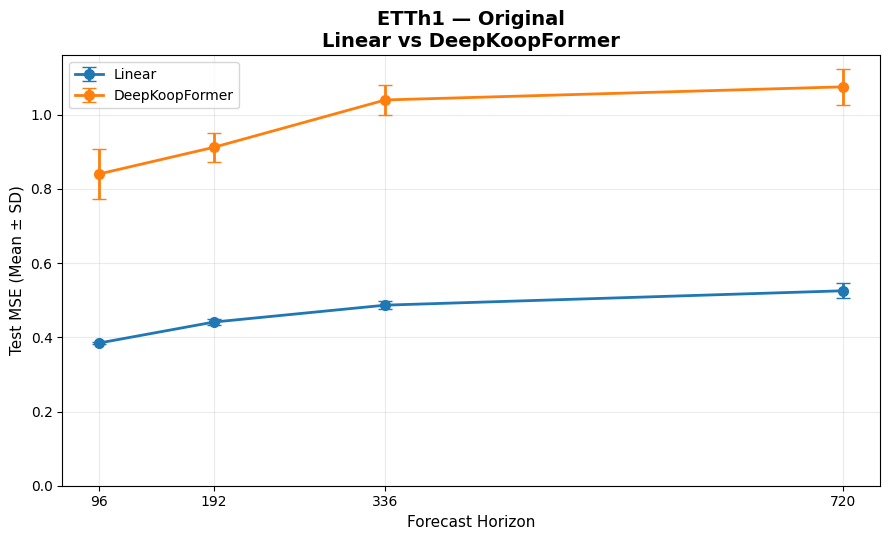

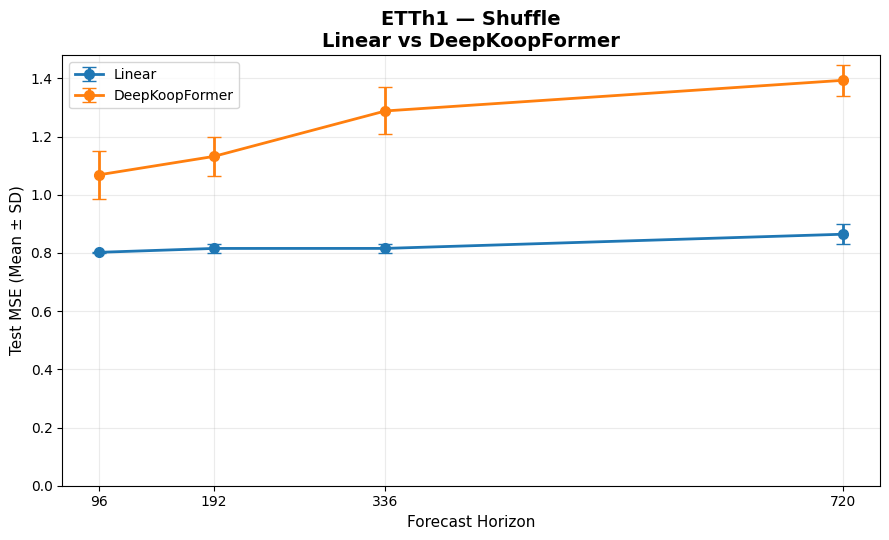

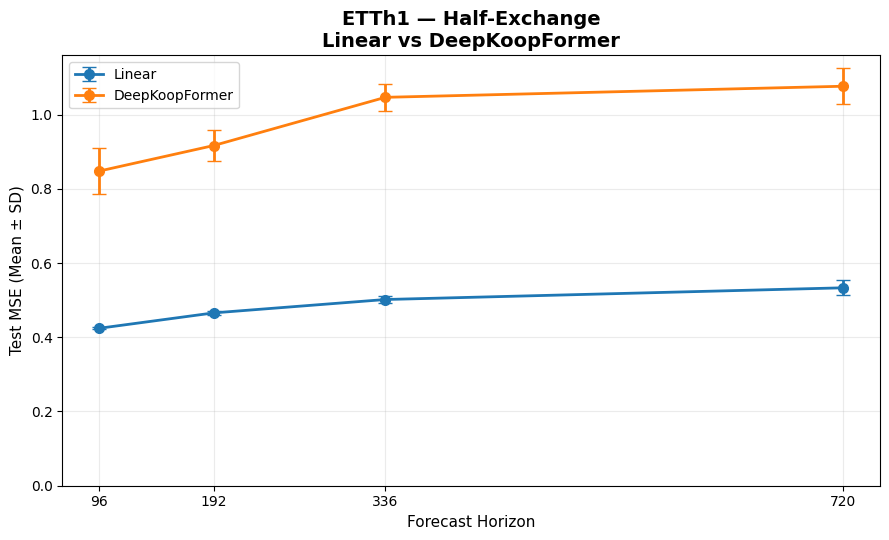

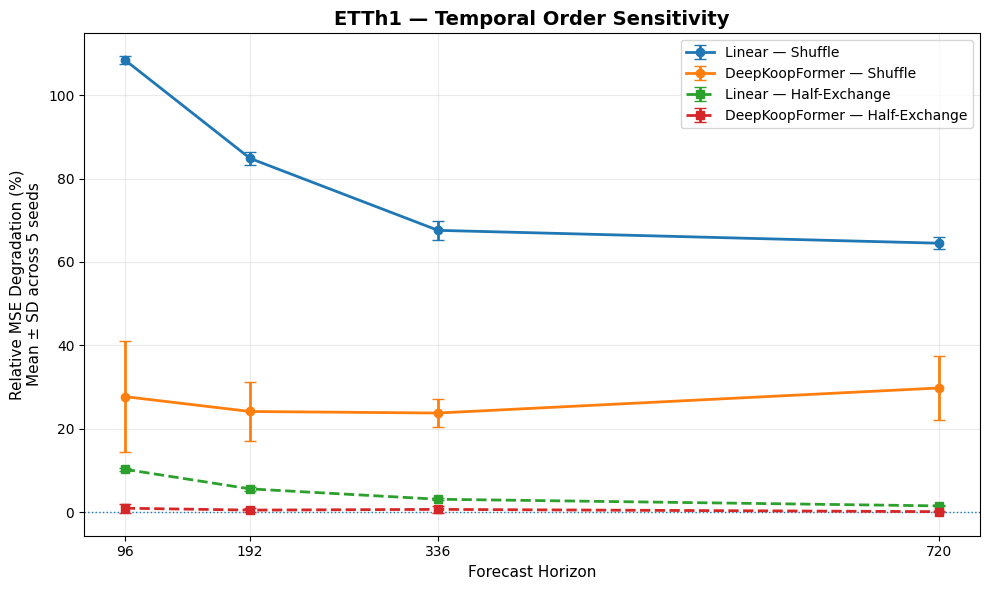


=== E7 FINAL VISUALIZATION ===
Summary groups: 24
Comparison groups: 12
Figures saved: 4
SAVED: e7_mse_original.png
SAVED: e7_mse_shuffle.png
SAVED: e7_mse_half_exchange.png
SAVED: e7_temporal_order_sensitivity.png

Output folder: C:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\e7_final_analysis\figures

E7 FINAL VISUALIZATION PASSED!


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    r"C:\Users\Win 11 New\Desktop\pa gk"
)

ANALYSIS_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "08_external_paper"
    / "results"
    / "e7_final_analysis"
)

FIGURE_DIR = ANALYSIS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

summary = pd.read_csv(
    ANALYSIS_DIR / "e7_summary_mean_sd.csv"
)

comparison = pd.read_csv(
    ANALYSIS_DIR / "e7_model_comparison.csv"
)

HORIZONS = [96, 192, 336, 720]
MODELS = ["Linear", "DeepKoopFormer"]

TRANSFORMATIONS = [
    "Original",
    "Shuffle",
    "Half-Exchange"
]

assert len(summary) == 24
assert len(comparison) == 12
assert (summary["N_Seeds"] == 5).all()

FIGURES_SAVED = []


# ------------------------------------------------------------
# FIGURES 1–3: Absolute Test MSE
# ------------------------------------------------------------
for transformation in TRANSFORMATIONS:

    fig, ax = plt.subplots(figsize=(9, 5.5))

    for model_name in MODELS:

        subset = summary[
            (summary["Model"] == model_name)
            & (
                summary["Transformation"]
                == transformation
            )
        ].sort_values("Horizon")

        assert len(subset) == 4

        ax.errorbar(
            subset["Horizon"],
            subset["MSE_Mean"],
            yerr=subset["MSE_SD"],
            marker="o",
            markersize=7,
            linewidth=2,
            capsize=5,
            label=model_name
        )

    ax.set_title(
        f"ETTh1 — {transformation}\n"
        "Linear vs DeepKoopFormer",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Forecast Horizon", fontsize=11)
    ax.set_ylabel("Test MSE (Mean ± SD)", fontsize=11)

    ax.set_xticks(HORIZONS)
    ax.set_ylim(bottom=0)

    ax.grid(alpha=0.25)
    ax.legend()

    fig.tight_layout()

    name = (
        "e7_mse_"
        + transformation.lower().replace("-", "_")
        + ".png"
    )

    path = FIGURE_DIR / name

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    FIGURES_SAVED.append(path)

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# FIGURE 4: Temporal Order Sensitivity
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

for transformation in [
    "Shuffle",
    "Half-Exchange"
]:

    for model_name in MODELS:

        subset = summary[
            (summary["Model"] == model_name)
            & (
                summary["Transformation"]
                == transformation
            )
        ].sort_values("Horizon")

        assert len(subset) == 4

        ax.errorbar(
            subset["Horizon"],
            subset["MSE_Degradation_Mean"],
            yerr=subset["MSE_Degradation_SD"],
            marker=(
                "o" if transformation == "Shuffle"
                else "s"
            ),
            linestyle=(
                "-" if transformation == "Shuffle"
                else "--"
            ),
            linewidth=2,
            capsize=4,
            label=f"{model_name} — {transformation}"
        )

ax.axhline(
    0,
    linestyle=":",
    linewidth=1
)

ax.set_title(
    "ETTh1 — Temporal Order Sensitivity",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Forecast Horizon", fontsize=11)

ax.set_ylabel(
    "Relative MSE Degradation (%)\n"
    "Mean ± SD across 5 seeds",
    fontsize=11
)

ax.set_xticks(HORIZONS)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

sensitivity_path = (
    FIGURE_DIR
    / "e7_temporal_order_sensitivity.png"
)

fig.savefig(
    sensitivity_path,
    dpi=300,
    bbox_inches="tight"
)

FIGURES_SAVED.append(sensitivity_path)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------
assert len(FIGURES_SAVED) == 4
assert all(p.is_file() for p in FIGURES_SAVED)

print("\n=== E7 FINAL VISUALIZATION ===")
print("Summary groups:", len(summary))
print("Comparison groups:", len(comparison))
print("Figures saved:", len(FIGURES_SAVED))

for path in FIGURES_SAVED:
    print("SAVED:", path.name)

print("\nOutput folder:", FIGURE_DIR)
print("\nE7 FINAL VISUALIZATION PASSED!")


FINAL EXPERIMENTAL INTEGRITY CHECK

In [6]:
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import torch

BASE = (
    Path(r"C:\Users\Win 11 New\Desktop\pa gk")
    / "experiments"
    / "08_external_paper"
    / "results"
)

HORIZONS = [96, 192, 336, 720]
SEEDS = [7, 17, 27, 37, 47]
TRANSFORMS = ["Original", "Shuffle", "Half-Exchange"]

EXPECTED = set(product(
    HORIZONS, SEEDS, TRANSFORMS
))

DATA_PATH = BASE / "etth1_data" / "etth1_prepared.pt"

MODEL_DIR = (
    BASE / "deepkoopformer_comparison" / "models"
)

ANALYSIS_DIR = BASE / "e7_final_analysis"

bundle = torch.load(
    DATA_PATH,
    map_location="cpu",
    weights_only=True
)

source_hash = bundle["source_sha256"]

# 1. Read verified comparison results
all_runs = pd.read_csv(
    ANALYSIS_DIR / "e7_all_runs.csv"
)

assert len(all_runs) == 120

for model_name in ["Linear", "DeepKoopFormer"]:
    subset = all_runs[
        all_runs["Model"] == model_name
    ]

    keys = set(zip(
        subset["Horizon"],
        subset["Seed"],
        subset["Transformation"]
    ))

    assert len(subset) == 60
    assert keys == EXPECTED

print("PASS: 60 evaluations per model")

# 2. Verify DeepKoopFormer checkpoint metrics
checked = 0

for h, seed in product(HORIZONS, SEEDS):

    model_path = MODEL_DIR / (
        f"koop_full_h{h}_seed{seed}.pt"
    )

    assert model_path.exists(), model_path

    ckpt = torch.load(
        model_path,
        map_location="cpu",
        weights_only=True
    )

    config = ckpt["config"]

    assert config["horizon"] == h
    assert config["seed"] == seed
    assert config["data_sha256"] == source_hash
    assert ckpt["epochs_trained"] == 4000

    row = all_runs[
        (all_runs["Model"] == "DeepKoopFormer")
        & (all_runs["Horizon"] == h)
        & (all_runs["Seed"] == seed)
        & (all_runs["Transformation"] == "Original")
    ]

    assert len(row) == 1

    np.testing.assert_allclose(
        row["MSE"].iloc[0],
        ckpt["scores"]["test"]["MSE"],
        rtol=1e-6,
        atol=1e-8
    )

    np.testing.assert_allclose(
        row["MAE"].iloc[0],
        ckpt["scores"]["test"]["MAE"],
        rtol=1e-6,
        atol=1e-8
    )

    checked += 1

print(f"PASS: {checked}/20 checkpoints verified")
print("PASS: ETTh1 source SHA256 consistent")
print("PASS: Original metrics match checkpoints")

# 3. Verify same test-window counts
test_length = len(bundle["test"])
seq_len = int(bundle["seq_len"])

expected_counts = {
    h: test_length - seq_len - h + 1
    for h in HORIZONS
}

assert expected_counts == {
    96: 2785,
    192: 2689,
    336: 2545,
    720: 2161
}

print("PASS: Expected test-window counts")

# 4. Check final summaries
summary = pd.read_csv(
    ANALYSIS_DIR / "e7_summary_mean_sd.csv"
)

comparison = pd.read_csv(
    ANALYSIS_DIR / "e7_model_comparison.csv"
)

paired = pd.read_csv(
    ANALYSIS_DIR / "e7_paired_seed_comparison.csv"
)

assert len(summary) == 24
assert len(comparison) == 12
assert len(paired) == 60

assert (summary["N_Seeds"] == 5).all()

print("PASS: Mean/SD aggregation")
print("PASS: Paired model comparisons")

# 5. Check figures
figure_dir = ANALYSIS_DIR / "figures"

expected_figures = [
    "e7_mse_original.png",
    "e7_mse_shuffle.png",
    "e7_mse_half_exchange.png",
    "e7_temporal_order_sensitivity.png"
]

for name in expected_figures:
    assert (figure_dir / name).is_file(), name

print("PASS: 4/4 figures")

print("\n========================================")
print("E7 EXPERIMENTAL INTEGRITY CHECK PASSED")
print("20/20 DeepKoopFormer checkpoints")
print("120/120 temporal evaluations")
print("24/24 statistical summary groups")
print("4/4 figures")
print("========================================")


PASS: 60 evaluations per model
PASS: 20/20 checkpoints verified
PASS: ETTh1 source SHA256 consistent
PASS: Original metrics match checkpoints
PASS: Expected test-window counts
PASS: Mean/SD aggregation
PASS: Paired model comparisons
PASS: 4/4 figures

E7 EXPERIMENTAL INTEGRITY CHECK PASSED
20/20 DeepKoopFormer checkpoints
120/120 temporal evaluations
24/24 statistical summary groups
4/4 figures
